  Peak proportion symptomatic (PI): 0.3707
  Month of peak                   : 60.0
  Final proportion susceptible    : 0.3632
  Final proportion exposed        : 0.2661
  Final proportion infected       : 0.3707


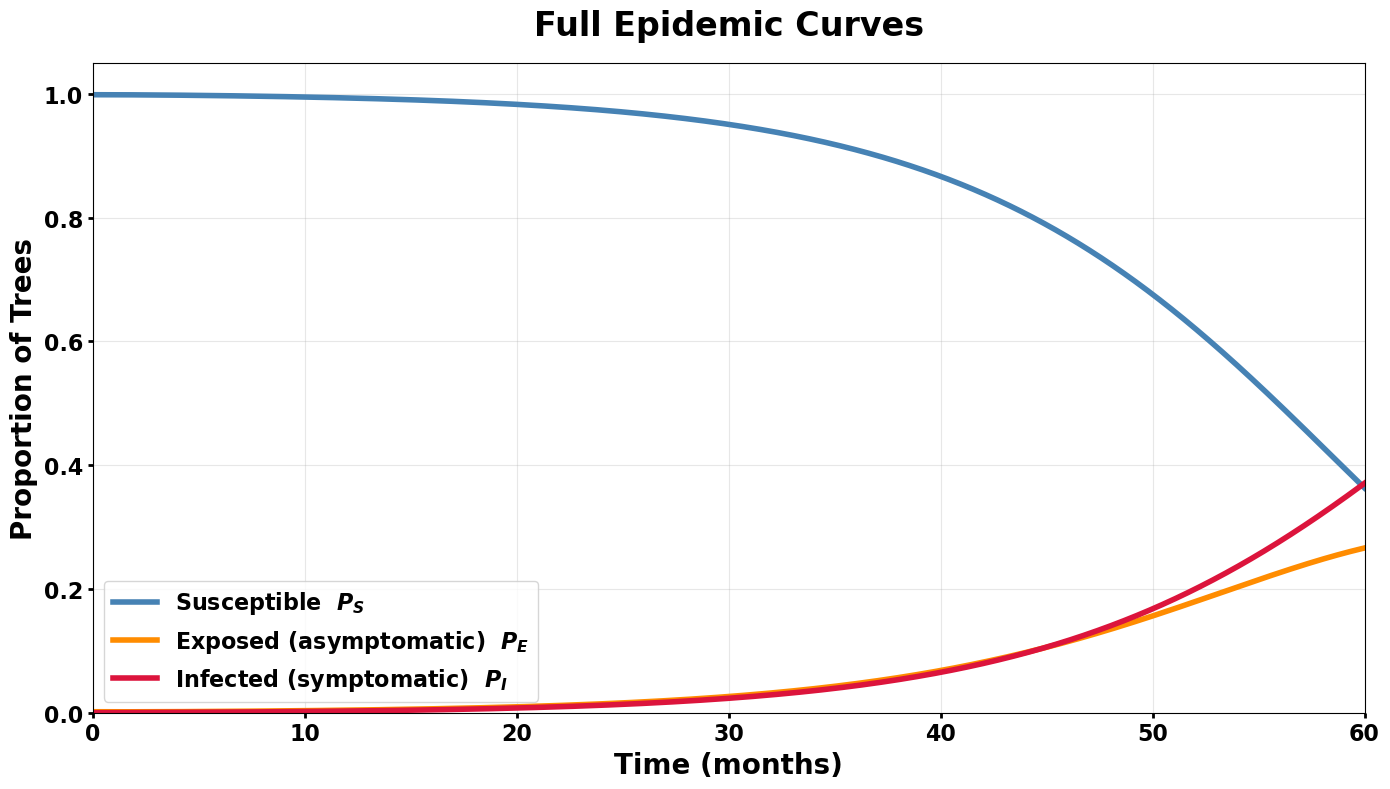

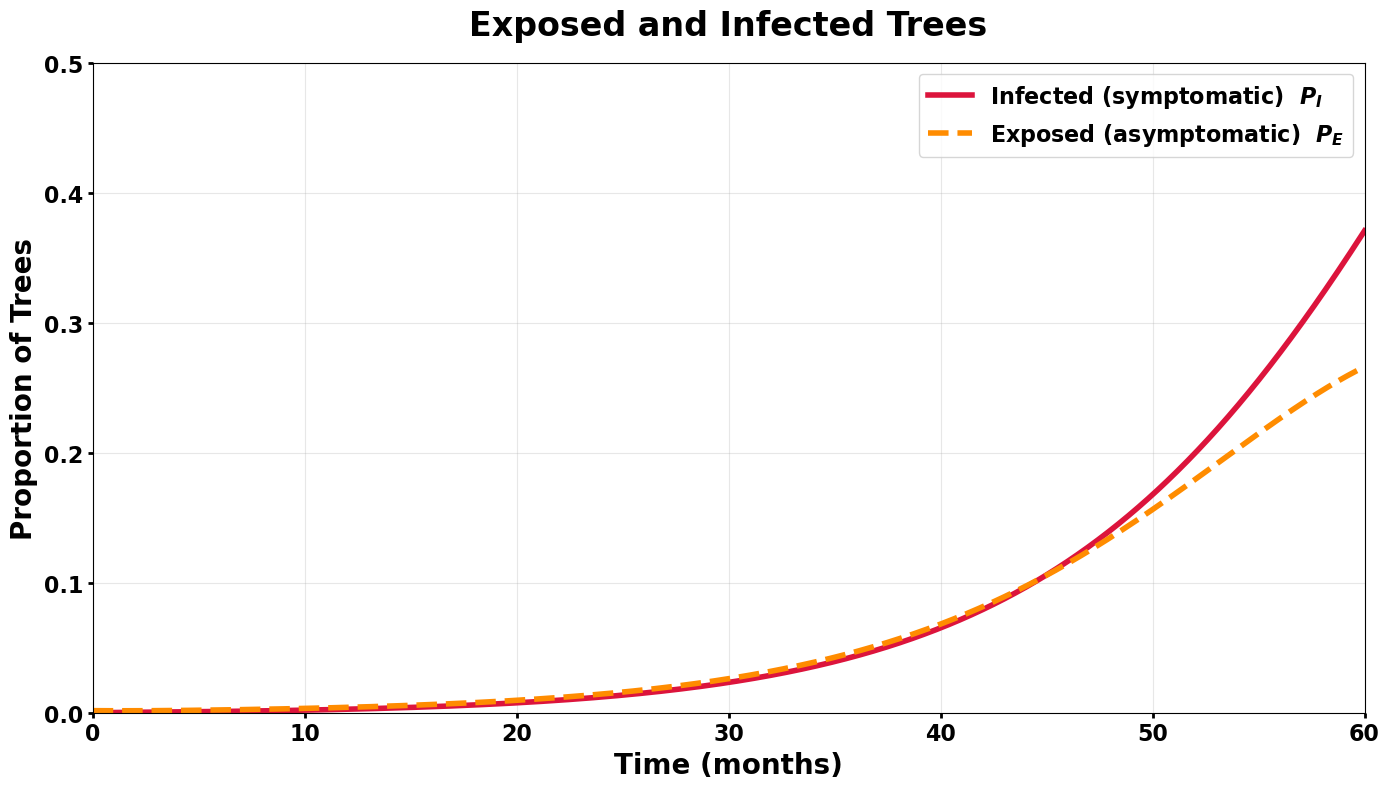

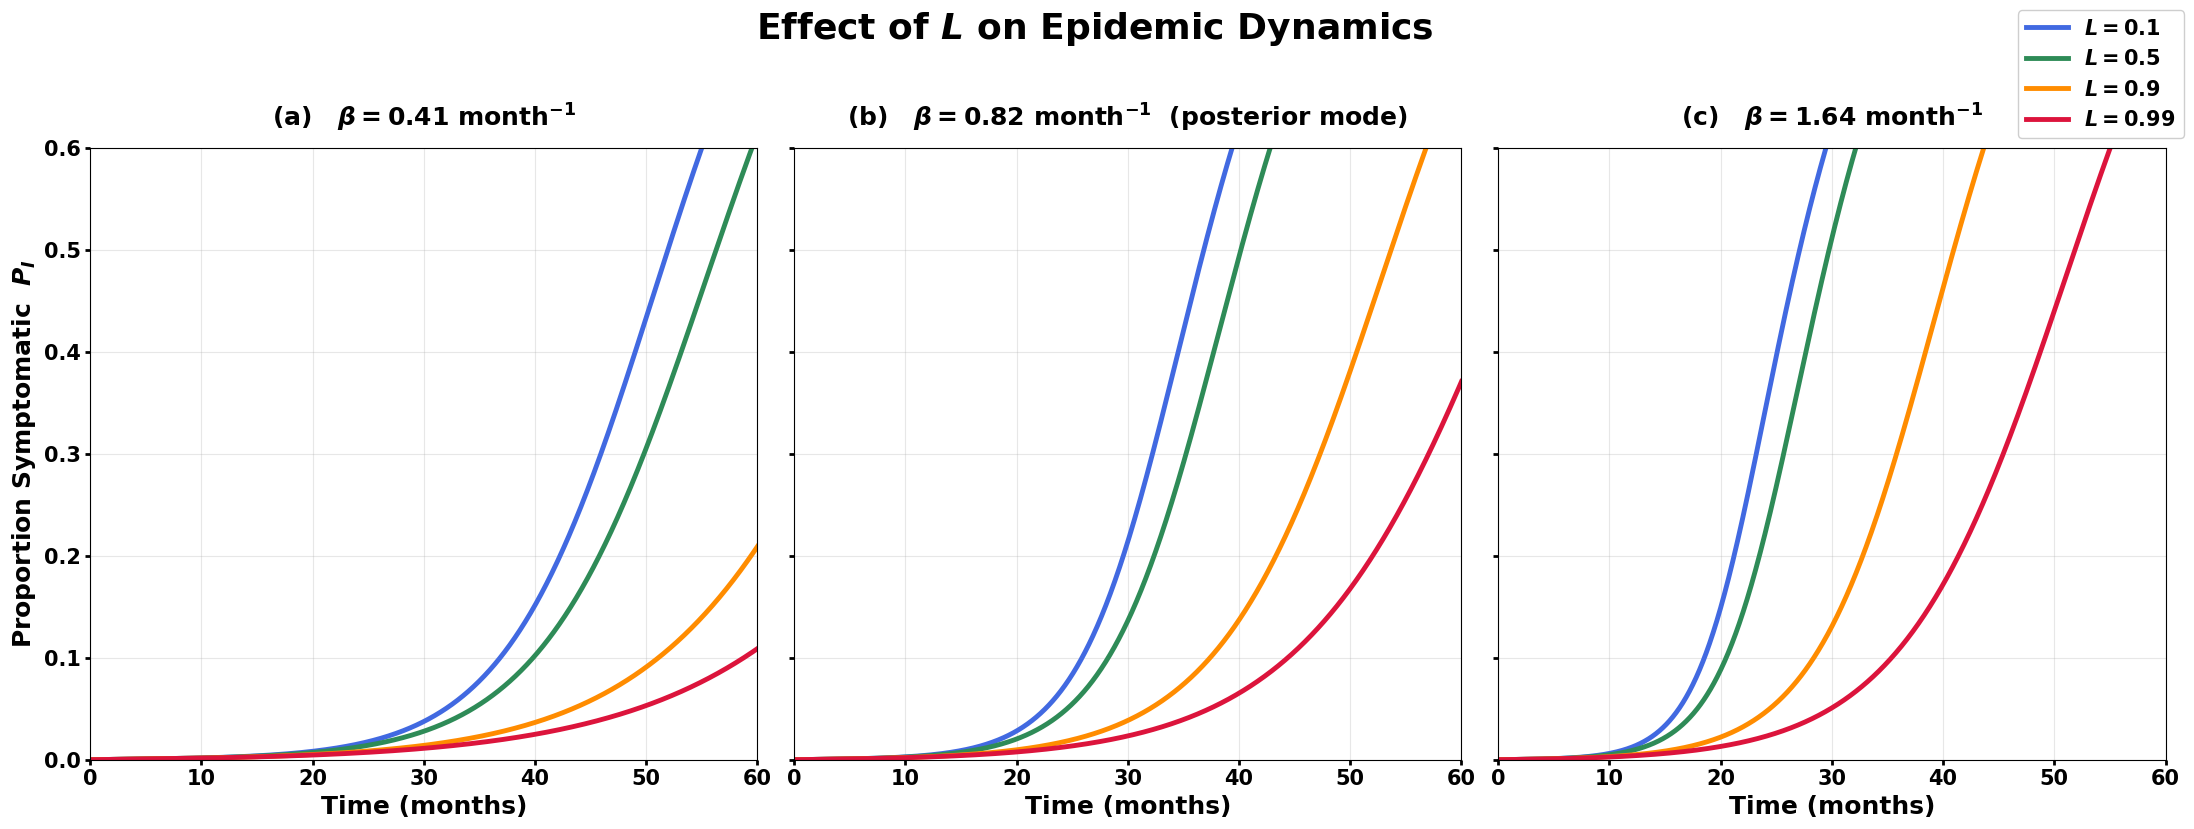

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


beta = 0.82          # transmission rate (per month, modal posterior)
rho  = 1.0 / 10.53  # progression rate E->I (latent period = 10.53 months)
L    = 0.99          # local-to-global ratio (modal posterior)


N_lattice = 625      # 25 x 25 lattice

# Time grid: 60 months = 5 years
t_start = 0
t_end   = 60
t_eval  = np.linspace(t_start, t_end, 2000)

# Initial conditions
PE_init = 1.0 / N_lattice # One asymptomatic (exposed) tree
PS_init = 1.0 - PE_init
PI_init = 0.0             # No infected tree

# Pair initial conditions 
PSS_init = PS_init * PS_init
PSE_init = PS_init * PE_init
PSI_init = 0.0              
PEE_init = PE_init * PE_init
PEI_init = 0.0               

# The SEI pair approximation ODE system 
def sei_pa_odes(t, y, beta, rho, L):

    PS, PE, PSS, PSE, PSI, PEE, PEI = y

    PI = 1.0 - PS - PE
    
    # Guard against division by zero when PS is very small
    if PS < 1e-12:
        qIS = 0.0
    else:
        qIS = PSI / PS    


    # Terms in singlet and pair equations
    inf_S = (1.0 - L) * PI + L * qIS


    inf_SS = (1.0 - L) * PI + (3.0/4.0) * L * qIS
    

    inf_SI = (1.0 - L) * PI + (1.0/4.0) * L + (3.0/4.0) * L * qIS

    # Singlet equations
    dPS = -beta * PS * inf_S

    dPE =  beta * PS * inf_S - rho * PE


    # Pair equations 

    dPSS = -2.0 * beta * PSS * inf_SS

    dPSE = (  beta * PSS * inf_SS
            - beta * PSE * inf_SS
            - rho  * PSE )

    dPSI = (  rho  * PSE
            - beta * PSI * inf_SI )

    dPEE = (  2.0 * beta * PSE * inf_SS
            - 2.0 * rho  * PEE )

    dPEI = (  rho  * PEE
            + beta * PSI * inf_SI
            - rho  * PEI )

    return [dPS, dPE, dPSS, dPSE, dPSI, dPEE, dPEI]


# Initial condition vector 
y0 = [PS_init, PE_init,
      PSS_init, PSE_init, PSI_init,
      PEE_init, PEI_init]

# Solve the 7 ODEs 
sol = solve_ivp(
    sei_pa_odes,
    [t_start, t_end],
    y0,
    args=(beta, rho, L),
    t_eval=t_eval,
    method='Radau',       
    rtol=1e-8,
    atol=1e-10,
    dense_output=False
)

# Extract solutions 
PS_sol = sol.y[0]
PE_sol = sol.y[1]
PI_sol = 1.0 - PS_sol - PE_sol  


# Key results 
print(f"  Peak proportion symptomatic (PI): {PI_sol.max():.4f}")
print(f"  Month of peak                   : "
      f"{sol.t[PI_sol.argmax()]:.1f}")
print(f"  Final proportion susceptible    : {PS_sol[-1]:.4f}")
print(f"  Final proportion exposed        : {PE_sol[-1]:.4f}")
print(f"  Final proportion infected       : {PI_sol[-1]:.4f}")



# =========================
# GLOBAL FONT SETTINGS
# =========================
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'


# FIGURE 1 -- Full SEI epidemic curves (S, E, I over time)
fig1, ax1 = plt.subplots(figsize=(14, 8))

ax1.plot(sol.t, PS_sol, color='steelblue', linewidth=4,
         label='Susceptible  $P_S$')
ax1.plot(sol.t, PE_sol, color='darkorange', linewidth=4,
         label='Exposed (asymptomatic)  $P_E$')
ax1.plot(sol.t, PI_sol, color='crimson', linewidth=4,
         label='Infected (symptomatic)  $P_I$')

ax1.set_title(
    'Full Epidemic Curves',
    fontsize=24,
    fontweight='bold',
    pad=20
)

ax1.set_xlabel('Time (months)',
               fontsize=20,
               fontweight='bold')

ax1.set_ylabel('Proportion of Trees',
               fontsize=20,
               fontweight='bold')

ax1.set_xlim([0, t_end])
ax1.set_ylim([0, 1.05])

ax1.legend(fontsize=16)

ax1.grid(True, alpha=0.3)

ax1.tick_params(axis='both',
                labelsize=16,
                width=2)

plt.tight_layout()

plt.savefig('SEI_figure1_full_curves.png',
            dpi=300,
            bbox_inches='tight')

plt.show()



# FIGURE 2 -- Exposed and Infected only (zoomed in)
fig2, ax2 = plt.subplots(figsize=(14, 8))

ax2.plot(sol.t, PI_sol, color='crimson', linewidth=4,
         label='Infected (symptomatic)  $P_I$')

ax2.plot(sol.t, PE_sol, color='darkorange', linewidth=4,
         linestyle='--',
         label='Exposed (asymptomatic)  $P_E$')

ax2.set_title(
    'Exposed and Infected Trees',
    fontsize=24,
    fontweight='bold',
    pad=20
)

ax2.set_xlabel('Time (months)',
               fontsize=20,
               fontweight='bold')

ax2.set_ylabel('Proportion of Trees',
               fontsize=20,
               fontweight='bold')

ax2.set_xlim([0, t_end])
ax2.set_ylim([0, 0.5])

ax2.legend(fontsize=16)

ax2.grid(True, alpha=0.3)

ax2.tick_params(axis='both',
                labelsize=16,
                width=2)

plt.tight_layout()

plt.savefig('SEI_figure2_infected_exposed.png',
            dpi=300,
            bbox_inches='tight')

plt.show()



# FIGURE 3 -- Effect of varying L on symptomatic infections
# Three panels: beta = 0.41, 0.82, 1.64 (half, mode, double)

L_values  = [0.1, 0.5, 0.90, 0.99]

colours_L = {
    0.1:  'royalblue',
    0.5:  'seagreen',
    0.90: 'darkorange',
    0.99: 'crimson'
}

beta_panels = [0.41, 0.82, 1.64]

panel_titles = [
    r'(a)   $\beta = 0.41$ month$^{-1}$',
    r'(b)   $\beta = 0.82$ month$^{-1}$  (posterior mode)',
    r'(c)   $\beta = 1.64$ month$^{-1}$'
]

fig3, axes3 = plt.subplots(1, 3,
                           figsize=(22, 8),
                           sharey=True)

fig3.suptitle(
    'Effect of $L$ on Epidemic Dynamics',
    fontsize=26,
    fontweight='bold',
    y=1.03
)

for ax3, beta_v, title_v in zip(axes3,
                                beta_panels,
                                panel_titles):

    for Lv in L_values:

        y0_v = [PS_init, PE_init,
                PSS_init, PSE_init, PSI_init,
                PEE_init, PEI_init]

        sol_v = solve_ivp(
            sei_pa_odes,
            [t_start, t_end],
            y0_v,
            args=(beta_v, rho, Lv),
            t_eval=t_eval,
            method='Radau',
            rtol=1e-8,
            atol=1e-10
        )

        PI_v = 1.0 - sol_v.y[0] - sol_v.y[1]

        ax3.plot(sol_v.t,
                 PI_v,
                 color=colours_L[Lv],
                 linewidth=3.5,
                 label=f'$L = {Lv}$')

    ax3.set_title(title_v,
                  fontsize=18,
                  fontweight='bold',
                  pad=15)

    ax3.set_xlabel('Time (months)',
                   fontsize=18,
                   fontweight='bold')

    ax3.set_xlim([0, t_end])

    ax3.set_ylim([0, 0.6])

    ax3.grid(True, alpha=0.3)

    ax3.tick_params(axis='both',
                    labelsize=15,
                    width=2)

axes3[0].set_ylabel('Proportion Symptomatic  $P_I$',
                    fontsize=18,
                    fontweight='bold')

handles3, lbls3 = axes3[0].get_legend_handles_labels()

fig3.legend(handles3,
            lbls3,
            loc='upper right',
            fontsize=15,
            framealpha=0.95)

plt.tight_layout()

plt.savefig('SEI_figure3_varying_L.png',
            dpi=300,
            bbox_inches='tight')

plt.show()